<a href="https://colab.research.google.com/github/akshat280706/IP-LABS/blob/main/241080009_akshat_IP_LAB5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#IP LAB5
#Akshat Chauhan
#241080009

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize, remove_small_objects

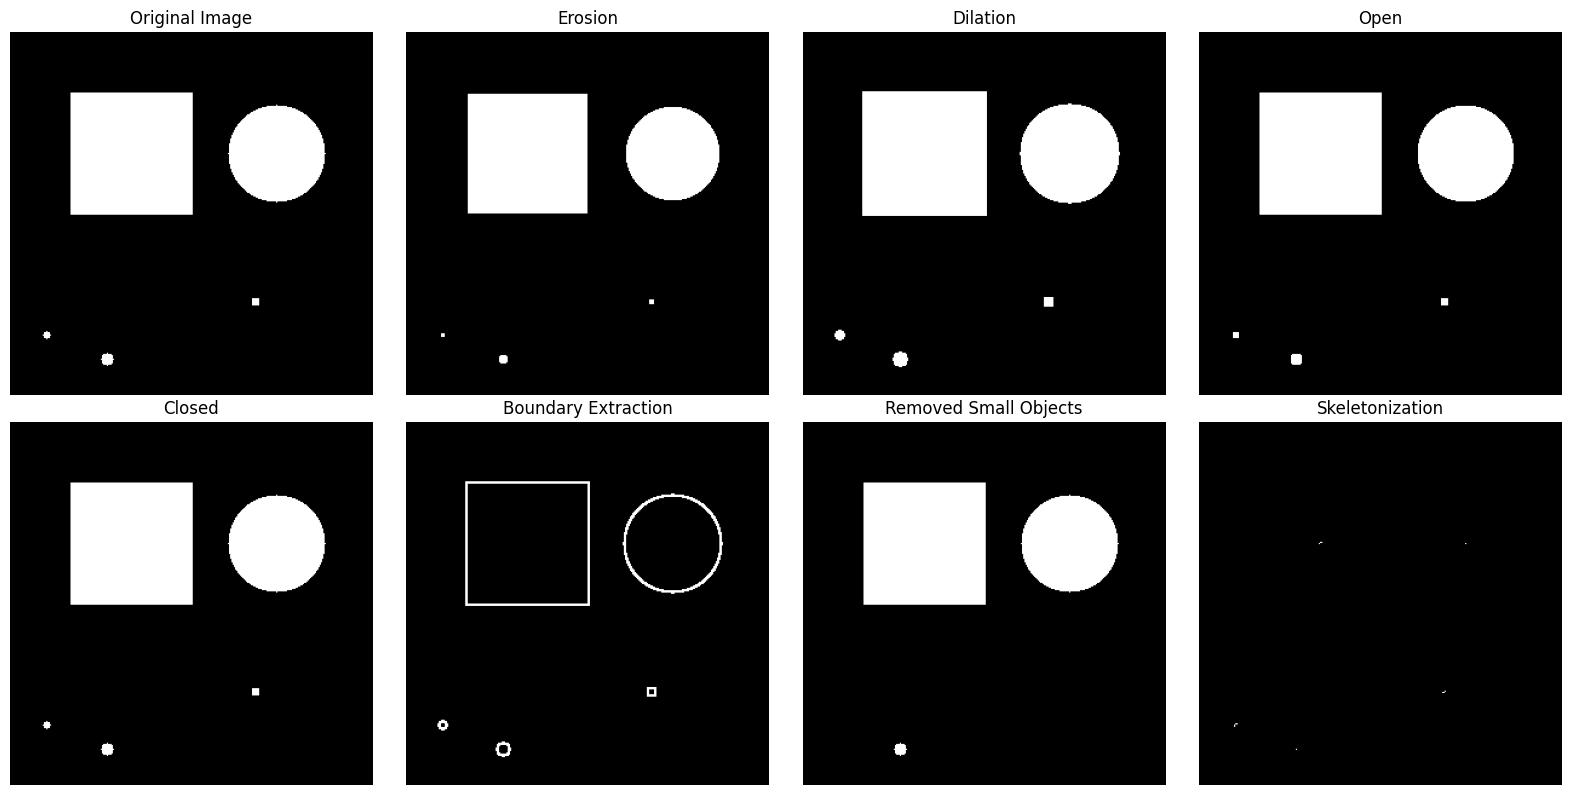

In [ ]:
image=np.zeros((300, 300), dtype=np.uint8)

cv2.rectangle(image,(50,50),(150,150),255,-1)
cv2.circle(image,(220,100),40,255,-1)
cv2.circle(image,(30,250),3,255,-1)
cv2.circle(image,(80,270),5,255,-1)
cv2.rectangle(image,(200,220),(205,225),255,-1)

kernel=np.ones((3,3),np.uint8)

eroded=cv2.erode(image,kernel,iterations=1)
dilated=cv2.dilate(image,kernel,iterations=1)

open=cv2.morphologyEx(image,cv2.MORPH_OPEN,kernel)
closed=cv2.morphologyEx(image,cv2.MORPH_CLOSE,kernel)

boundary=cv2.morphologyEx(image,cv2.MORPH_GRADIENT,kernel)

bool_image=image>0
cleaned_bool=remove_small_objects(bool_image,min_size=50)
cleaned_objects=(cleaned_bool*255).astype(np.uint8)

skeleton_bool=skeletonize(bool_image)
skeleton=(skeleton_bool*255).astype(np.uint8)

titles=['Original Image','Erosion','Dilation','Open','Closed',
        'Boundary Extraction','Removed Small Objects','Skeletonization']
images=[image,eroded,dilated,open,closed,boundary,cleaned_objects,skeleton]

plt.figure(figsize=(16,8))
for i in range(8):
    plt.subplot(2,4,i+1)
    plt.imshow(images[i],cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()